In [20]:

## Installing and Importing Required Libraries


In [21]:

# Install all required libraries
!pip -q install pandas numpy yfinance requests lxml html5lib scipy scikit-learn matplotlib seaborn pyarrow openpyxl


In [22]:

# Data analysis
import pandas as pd
import numpy as np

# Data acquisition
import yfinance as yf
import requests
from io import StringIO
from datetime import datetime, timezone

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

# Hierarchical clustering
from scipy.cluster.hierarchy import linkage, dendrogram

# Google Colab file management
from google.colab import files

# Display settings
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

print("All libraries imported successfully!")


All libraries imported successfully!



## 1.1 Ticker Selection and Data Acquisition

S&P 500 constituent information and historical daily stock data are used for the analysis covering 2021–2024.


In [23]:

# 1.1 Ticker Selection and Data Acquisition

# Download the current S&P 500 constituent list
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

headers = {
    "User-Agent": "StudentResearch/1.0 (educational analysis)"
}

response = requests.get(url, headers=headers, timeout=30)
response.raise_for_status()

sp500 = pd.read_html(StringIO(response.text))[0]

sp500["YahooTicker"] = (
    sp500["Symbol"].str.replace(".", "-", regex=False)
)

tickers = sp500["YahooTicker"].tolist()

print("Total S&P 500 tickers:", len(tickers))

# Download historical stock data
start_date = "2021-01-01"
end_date = "2025-01-01"

all_tickers = list(dict.fromkeys(tickers + ["^GSPC"]))

downloaded_batches = []

for i in range(0, len(all_tickers), 25):

    batch = all_tickers[i:i + 25]

    print("Downloading batch:", i // 25 + 1)

    batch_data = yf.download(
        batch,
        start=start_date,
        end=end_date,
        auto_adjust=False,
        actions=True,
        group_by="ticker",
        threads=False,
        progress=False
    )

    if not batch_data.empty:
        downloaded_batches.append(batch_data)

stock_data = pd.concat(downloaded_batches, axis=1)

# Save downloaded data for reproducibility
sp500.to_csv("sp500_constituents.csv", index=False)
stock_data.to_pickle("sp500_daily_raw.pkl")

print("\nHistorical data downloaded successfully!")
print("Dataset shape:", stock_data.shape)
print("Date range:", stock_data.index.min(), "to",
      stock_data.index.max())

print("Benchmark included:",
      "^GSPC" in stock_data.columns.get_level_values("Ticker"))

display(sp500.head())
display(stock_data.iloc[:5, :8])


Total S&P 500 tickers: 503


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')



Historical data downloaded successfully!
Dataset shape: (1005, 4022)
Date range: 2021-01-04 00:00:00 to 2024-12-31 00:00:00
Benchmark included: True


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded,YahooTicker
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902,MMM
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916,AOS
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888,ABT
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888),ABBV
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989,ACN


Ticker           AMCR                                                                            
Price            Open       High        Low      Close  Adj Close   Volume Dividends Stock Splits
Date                                                                                             
2021-01-04  58.500000  58.849998  56.750000  56.900002  43.004169  1490420       0.0          0.0
2021-01-05  56.750000  57.750000  56.750000  57.299999  43.306488  1531480       0.0          0.0
2021-01-06  57.400002  59.400002  57.400002  58.900002  44.515736  1491520       0.0          0.0
2021-01-07  58.599998  58.849998  57.900002  58.400002  44.137844  1157580       0.0          0.0
2021-01-08  58.200001  58.549999  56.750000  57.500000  43.457638   743540       0.0          0.0


## 1.2 Data Validation and Alignment

The dataset is checked for missing values, invalid prices, volume errors, duplicate dates, corporate actions and unequal trading histories.


In [24]:

# Validate all downloaded ticker records

validation_results = []

for ticker in stock_data.columns.get_level_values("Ticker").unique():

    df = stock_data[ticker].copy()

    close = pd.to_numeric(df["Close"], errors="coerce")
    adj = pd.to_numeric(df["Adj Close"], errors="coerce")
    volume = pd.to_numeric(df["Volume"], errors="coerce")

    valid = (
        close.notna()
        & adj.notna()
        & volume.notna()
        & (close > 0)
        & (adj > 0)
        & (volume >= 0)
    )

    dates = df.index[valid]

    has_splits = "Stock Splits" in df.columns
    has_dividends = "Dividends" in df.columns

    split_events = (
        int((df["Stock Splits"].fillna(0) != 0).sum())
        if has_splits else np.nan
    )

    dividend_events = (
        int((df["Dividends"].fillna(0) != 0).sum())
        if has_dividends else np.nan
    )

    validation_results.append({
        "Ticker": ticker,
        "ValidDays": int(valid.sum()),
        "MissingClose": int(close.isna().sum()),
        "MissingAdjClose": int(adj.isna().sum()),
        "MissingVolume": int(volume.isna().sum()),
        "InvalidPrices": int(((close <= 0) | (adj <= 0)).sum()),
        "NegativeVolume": int((volume < 0).sum()),
        "ZeroVolume": int((volume == 0).sum()),
        "FirstValidDate": dates.min() if len(dates) else pd.NaT,
        "LastValidDate": dates.max() if len(dates) else pd.NaT,
        "SplitsColumnPresent": has_splits,
        "DividendsColumnPresent": has_dividends,
        "SplitEvents": split_events,
        "DividendEvents": dividend_events,
        "Status": (
            "No valid data" if valid.sum() == 0
            else "Short history - review" if valid.sum() < 900
            else "Data available - review"
        )
    })

validation = pd.DataFrame(validation_results)

print("Total symbols:", len(validation))
print("Duplicate dates:", stock_data.index.duplicated().sum())

print("\nValidation summary:")
display(validation["Status"].value_counts())

print("\nUnavailable symbols:")
display(validation[validation["ValidDays"] == 0])

print("\nShort histories:")
display(
    validation[
        (validation["ValidDays"] > 0)
        & (validation["ValidDays"] < 900)
    ]
)

validation.to_csv("validation_report.csv", index=False)

print("Validation report saved!")


Total symbols: 504
Duplicate dates: 0

Validation summary:


,count
Status,
Data available - review,492
Short history - review,7
No valid data,5



Unavailable symbols:


,Ticker,ValidDays,MissingClose,MissingAdjClose,MissingVolume,InvalidPrices,NegativeVolume,ZeroVolume,FirstValidDate,LastValidDate,SplitsColumnPresent,DividendsColumnPresent,SplitEvents,DividendEvents,Status
193,FDXF,0,1005,1005,1005,0,0,0,NaT,NaT,False,False,NaN,NaN,No valid data
227,HONA,0,1005,1005,1005,0,0,0,NaT,NaT,False,False,NaN,NaN,No valid data
386,Q,0,1005,1005,1005,0,0,0,NaT,NaT,False,False,NaN,NaN,No valid data
418,SNDK,0,1005,1005,1005,0,0,0,NaT,NaT,False,False,NaN,NaN,No valid data
496,VYLR,0,1005,1005,1005,0,0,0,NaT,NaT,False,False,NaN,NaN,No valid data



Short histories:


,Ticker,ValidDays,MissingClose,MissingAdjClose,MissingVolume,InvalidPrices,NegativeVolume,ZeroVolume,FirstValidDate,LastValidDate,SplitsColumnPresent,DividendsColumnPresent,SplitEvents,DividendEvents,Status
112,CEG,742,263,263,263,0,0,0,2022-01-19,2024-12-31,True,True,0.0,12.0,Short history - review
205,GEHC,513,492,492,492,0,0,0,2022-12-15,2024-12-31,True,True,0.0,7.0,Short history - review
214,GEV,193,812,812,812,0,0,0,2024-03-27,2024-12-31,True,True,0.0,1.0,Short history - review
379,HOOD,862,143,143,143,0,0,0,2021-07-29,2024-12-31,True,True,0.0,0.0,Short history - review
394,RDDT,197,808,808,808,0,0,0,2024-03-21,2024-12-31,True,True,0.0,0.0,Short history - review
406,SOLV,194,811,811,811,0,0,0,2024-03-26,2024-12-31,True,True,0.0,0.0,Short history - review
460,VLTO,313,692,692,692,0,0,0,2023-10-04,2024-12-31,True,True,0.0,5.0,Short history - review


Validation report saved!



## 1.3 Weekly Return and Weekly Beta

Mean weekly returns and weekly beta are calculated using Friday-ending adjusted closing prices and aligned S&P 500 benchmark returns.


In [25]:

# Extract adjusted closing prices
prices = stock_data.xs(
    "Adj Close", axis=1, level="Price"
).copy()

prices = prices.where(prices > 0)

# Convert daily prices to Friday-ending weekly prices
weekly_prices = prices.resample("W-FRI").last()

# Remove incomplete first and final calendar weeks
weekly_prices = weekly_prices.loc[
    "2021-01-08":"2024-12-27"
]

# Calculate weekly returns without filling missing values
weekly_returns = weekly_prices.pct_change(fill_method=None)

weekly_returns = weekly_returns.where(
    weekly_prices.notna()
    & weekly_prices.shift(1).notna()
)

# Extract the S&P 500 benchmark return
benchmark = weekly_returns["^GSPC"]

feature_results = []

for ticker in weekly_returns.columns:

    if ticker == "^GSPC":
        continue

    paired = pd.concat(
        [
            weekly_returns[ticker].rename("Share"),
            benchmark.rename("Market")
        ],
        axis=1
    ).dropna()

    if len(paired) < 2:
        continue

    market_variance = paired["Market"].var()

    if market_variance <= 0:
        continue

    # Arithmetic mean weekly return
    mean_return = paired["Share"].mean()

    # Weekly beta
    beta = (
        paired["Share"].cov(paired["Market"])
        / market_variance
    )

    feature_results.append({
        "Ticker": ticker,
        "AlignedWeeks": len(paired),
        "MeanWeeklyReturn": mean_return,
        "MeanWeeklyReturnPct": mean_return * 100,
        "WeeklyBeta": beta
    })

returns_beta = pd.DataFrame(feature_results)

print("Shares calculated:", len(returns_beta))
print("Weekly price periods:", len(weekly_prices))

print("\nFirst 10 results:")
display(returns_beta.head(10))

print("\nSummary statistics:")
display(
    returns_beta[
        ["MeanWeeklyReturnPct", "WeeklyBeta"]
    ].describe()
)

returns_beta.to_csv(
    "weekly_return_beta_features.csv",
    index=False
)

print("Weekly return and beta features saved!")


Shares calculated: 498
Weekly price periods: 208

First 10 results:


,Ticker,AlignedWeeks,MeanWeeklyReturn,MeanWeeklyReturnPct,WeeklyBeta
0,AMCR,207,0.000332,0.033174,0.671180
1,AMD,207,0.003624,0.362408,1.877622
2,AFL,207,0.005004,0.500423,0.707196
3,AMZN,207,0.002681,0.268113,1.386667
4,APD,207,0.001183,0.118286,0.708584
5,ABT,207,0.000971,0.097133,0.583543
6,ARE,207,-0.001101,-0.110050,1.160051
7,ALLE,207,0.001412,0.141180,1.033137
8,ACN,207,0.002376,0.237638,1.143300
9,ALGN,207,-0.002564,-0.256362,1.835953



Summary statistics:


,MeanWeeklyReturnPct,WeeklyBeta
count,498.000000,498.000000
mean,0.303484,0.984162
std,0.330440,0.427134
min,-0.446809,0.055453
25%,0.121606,0.671472
50%,0.268899,0.954712
75%,0.432060,1.188554
max,3.849094,3.778560


Weekly return and beta features saved!



## 1.4 Adapted RFM Calculations

Recency, Frequency and Monetary are calculated using the historical trading-volume threshold and the final 60 trading sessions.


In [26]:

observation_date = pd.Timestamp("2024-12-31")

rfm_results = []
rfm_audit = []
worked_examples = {}

# Common market trading dates
market_dates = stock_data["^GSPC"].index[
    stock_data["^GSPC"]["Close"].notna()
]

market_dates = market_dates[
    market_dates <= observation_date
]

for ticker in returns_beta["Ticker"]:

    df = stock_data[ticker][["Close", "Volume"]].copy()
    df = df.loc[:observation_date].sort_index()

    valid = (
        df["Close"].notna()
        & df["Volume"].notna()
        & (df["Close"] > 0)
        & (df["Volume"] >= 0)
    )

    valid_df = df.loc[valid].copy()

    # Assess gaps after the share's first valid date
    if not valid_df.empty:
        expected = market_dates[
            market_dates >= valid_df.index.min()
        ]

        missing_sessions = len(
            expected.difference(valid_df.index)
        )
    else:
        missing_sessions = np.nan

    rfm_audit.append({
        "Ticker": ticker,
        "ValidSessions": len(valid_df),
        "MissingMarketSessions": missing_sessions,
        "EndsOnObservationDate": (
            not valid_df.empty
            and valid_df.index.max() == observation_date
        )
    })

    if len(valid_df) < 80:
        continue

    if valid_df.index.max() != observation_date:
        continue

    # Rolling 20-session mean excluding current session
    valid_df["Previous20Mean"] = (
        valid_df["Volume"]
        .shift(1)
        .rolling(20, min_periods=20)
        .mean()
    )

    valid_df["Threshold"] = (
        2 * valid_df["Previous20Mean"]
    )

    valid_df["HighVolumeEvent"] = (
        (valid_df["Volume"] > valid_df["Threshold"])
        & valid_df["Threshold"].notna()
    )

    last_60 = valid_df.tail(60)

    # Recency: most recent qualifying event
    events = valid_df.loc[valid_df["HighVolumeEvent"]]

    if events.empty:
        recency = np.nan
        latest_event = pd.NaT
    else:
        latest_event = events.index.max()
        recency = (observation_date - latest_event).days

    # Frequency: qualifying days in last 60 sessions
    frequency = int(last_60["HighVolumeEvent"].sum())

    # Monetary: Close multiplied by Volume
    monetary = float(
        (last_60["Close"] * last_60["Volume"]).sum()
    )

    rfm_results.append({
        "Ticker": ticker,
        "Recency": recency,
        "Frequency": frequency,
        "Monetary": monetary,
        "LatestHighVolumeDate": latest_event,
        "ObservationDate": observation_date
    })

    if ticker == "ADBE":
        worked_examples["ADBE"] = last_60.copy()

rfm = pd.DataFrame(rfm_results)
rfm_gap_audit = pd.DataFrame(rfm_audit)

print("RFM shares:", len(rfm))
print("Missing Recency:", rfm["Recency"].isna().sum())

print("\nFirst 10 RFM results:")
display(rfm.head(10))

print("\nRFM summary:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())

print("\nShares with potential missing sessions:")
display(
    rfm_gap_audit[
        rfm_gap_audit["MissingMarketSessions"] > 0
    ].head(20)
)

rfm.to_csv("rfm_features.csv", index=False)
rfm_gap_audit.to_csv("rfm_gap_audit.csv", index=False)

if "ADBE" in worked_examples:
    worked_examples["ADBE"].to_csv(
        "ADBE_RFM_worked_example.csv"
    )

print("RFM calculations and audit saved!")


RFM shares: 498
Missing Recency: 0

First 10 RFM results:


,Ticker,Recency,Frequency,Monetary,LatestHighVolumeDate,ObservationDate
0,AMCR,11,6,7.685901e+09,2024-12-20,2024-12-31
1,AMD,18,4,3.131659e+11,2024-12-13,2024-12-31
2,AFL,11,2,1.328456e+10,2024-12-20,2024-12-31
3,AMZN,11,5,4.681770e+11,2024-12-20,2024-12-31
4,APD,85,1,2.662261e+10,2024-10-07,2024-12-31
5,ABT,11,1,3.523027e+10,2024-12-20,2024-12-31
6,ARE,11,1,8.493121e+09,2024-12-20,2024-12-31
7,ALLE,11,2,7.110592e+09,2024-12-20,2024-12-31
8,ACN,11,2,5.199430e+10,2024-12-20,2024-12-31
9,ALGN,11,4,1.067663e+10,2024-12-20,2024-12-31



RFM summary:


,Recency,Frequency,Monetary
count,498.000000,498.000000,4.980000e+02
mean,20.510040,3.004016,3.961352e+10
std,21.247722,1.327614,1.278859e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.025102e+10
50%,11.000000,3.000000,1.679667e+10
75%,18.000000,4.000000,3.287502e+10
max,222.000000,8.000000,1.847697e+12



Shares with potential missing sessions:


,Ticker,ValidSessions,MissingMarketSessions,EndsOnObservationDate


RFM calculations and audit saved!



## 1.5 Metric Interpretation and Supporting Evidence

The financial and RFM features are combined, checked for completeness and summarised before stock clustering.


In [27]:

# Merge weekly return, beta and RFM features
combined = pd.merge(
    returns_beta,
    rfm,
    on="Ticker",
    how="inner",
    validate="one_to_one"
)

required_features = [
    "MeanWeeklyReturn",
    "WeeklyBeta",
    "Recency",
    "Frequency",
    "Monetary"
]

# Check for missing and non-finite values
combined = combined.replace(
    [np.inf, -np.inf], np.nan
)

print("Combined shares:", len(combined))

print("\nMissing values:")
display(combined[required_features].isna().sum())

# Review short weekly histories
print("\nShares with fewer than 200 aligned weeks:")
display(
    combined.loc[
        combined["AlignedWeeks"] < 200,
        ["Ticker", "AlignedWeeks"]
    ].sort_values("AlignedWeeks")
)

# Preliminary shared set for the two clustering analyses
common_features = combined.dropna(
    subset=required_features
).copy()

print("\nPreliminary common shares:", len(common_features))

print("\nFeature summary:")
display(common_features[required_features].describe())

# Worked RFM example
print("\nADBE worked example:")
display(
    common_features.loc[
        common_features["Ticker"] == "ADBE",
        ["Ticker", "Recency", "Frequency",
         "Monetary", "LatestHighVolumeDate"]
    ]
)

# Save evidence
combined.to_csv(
    "combined_features_review.csv", index=False
)

common_features.to_csv(
    "common_features_preliminary.csv", index=False
)

print("\nTask 1 feature files saved successfully!")


Combined shares: 498

Missing values:


,0
MeanWeeklyReturn,0
WeeklyBeta,0
Recency,0
Frequency,0
Monetary,0



Shares with fewer than 200 aligned weeks:


,Ticker,AlignedWeeks
403,SOLV,39
213,GEV,39
391,RDDT,40
456,VLTO,64
204,GEHC,106
112,CEG,153
377,HOOD,178
121,COIN,193
27,APP,193



Preliminary common shares: 498

Feature summary:


,MeanWeeklyReturn,WeeklyBeta,Recency,Frequency,Monetary
count,498.000000,498.000000,498.000000,498.000000,4.980000e+02
mean,0.003035,0.984162,20.510040,3.004016,3.961352e+10
std,0.003304,0.427134,21.247722,1.327614,1.278859e+11
min,-0.004468,0.055453,4.000000,0.000000,1.297483e+09
25%,0.001216,0.671472,11.000000,2.000000,1.025102e+10
50%,0.002689,0.954712,11.000000,3.000000,1.679667e+10
75%,0.004321,1.188554,18.000000,4.000000,3.287502e+10
max,0.038491,3.778560,222.000000,8.000000,1.847697e+12



ADBE worked example:


,Ticker,Recency,Frequency,Monetary,LatestHighVolumeDate
21,ADBE,18,3,1.030403e+11,2024-12-13



Task 1 feature files saved successfully!



# Task 2 — Stock Segmentation and Sensitivity Analysis
## 2.1 Feature Preparation


In [28]:

# Load Task 1 feature results
data = pd.read_csv("common_features_preliminary.csv")

# Use the same shares for both feature matrices
required = [
    "MeanWeeklyReturn", "WeeklyBeta",
    "Recency", "Frequency", "Monetary"
]

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=required).copy()

# Check data validity
assert data["Ticker"].is_unique
assert (data["Monetary"] >= 0).all()

print("Common shares:", len(data))

# Examine skewness before transformation
print("\nOriginal feature skewness:")
display(data[required].skew().to_frame("Skewness"))

# Examine outliers using the IQR method
outlier_results = []

for col in required:
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = (
        (data[col] < lower) |
        (data[col] > upper)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "IQR_Outliers": int(count)
    })

outlier_summary = pd.DataFrame(outlier_results)

print("\nOutlier summary:")
display(outlier_summary)

# Prepare risk-return features
risk_return = data[
    ["MeanWeeklyReturn", "WeeklyBeta"]
].copy()

# Prepare RFM features
rfm_features = data[
    ["Recency", "Frequency", "Monetary"]
].copy()

# Required Monetary log transformation
rfm_features["LogMonetary"] = np.log1p(
    rfm_features["Monetary"]
)

print("\nMonetary skewness comparison:")
print("Original:", data["Monetary"].skew())
print("Log transformed:", rfm_features["LogMonetary"].skew())

# Standardise each matrix separately
risk_scaler = StandardScaler()
rfm_scaler = StandardScaler()

X_risk = risk_scaler.fit_transform(
    risk_return
)

X_rfm = rfm_scaler.fit_transform(
    rfm_features[
        ["Recency", "Frequency", "LogMonetary"]
    ]
)

print("\nRisk-return shape:", X_risk.shape)
print("RFM shape:", X_rfm.shape)

# Save results
outlier_summary.to_csv(
    "feature_outlier_summary.csv", index=False
)

pd.DataFrame(
    X_risk,
    columns=["Return", "Beta"],
    index=data["Ticker"]
).to_csv("risk_return_scaled.csv")

pd.DataFrame(
    X_rfm,
    columns=["Recency", "Frequency", "LogMonetary"],
    index=data["Ticker"]
).to_csv("rfm_scaled.csv")

print("\nTask 2.1 completed!")


Common shares: 498

Original feature skewness:


,Skewness
MeanWeeklyReturn,3.555524
WeeklyBeta,1.248599
Recency,3.610175
Frequency,0.407012
Monetary,11.739518



Outlier summary:


,Feature,IQR_Outliers
0,MeanWeeklyReturn,19
1,WeeklyBeta,12
2,Recency,97
3,Frequency,2
4,Monetary,46



Monetary skewness comparison:
Original: 11.739517630960602
Log transformed: 1.049212190674137

Risk-return shape: (498, 2)
RFM shape: (498, 3)

Task 2.1 completed!



## 2.2 Agglomerative Hierarchical Clustering

Ward linkage with Euclidean distance is applied to the standardised risk-return and RFM feature matrices.


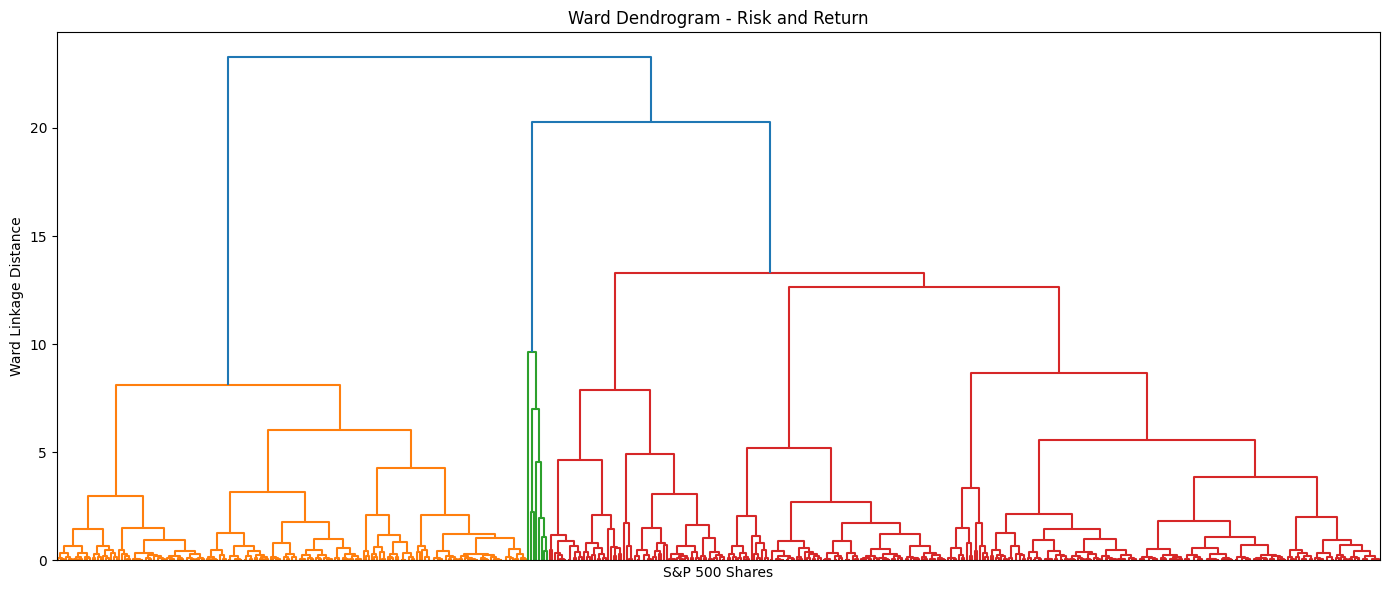

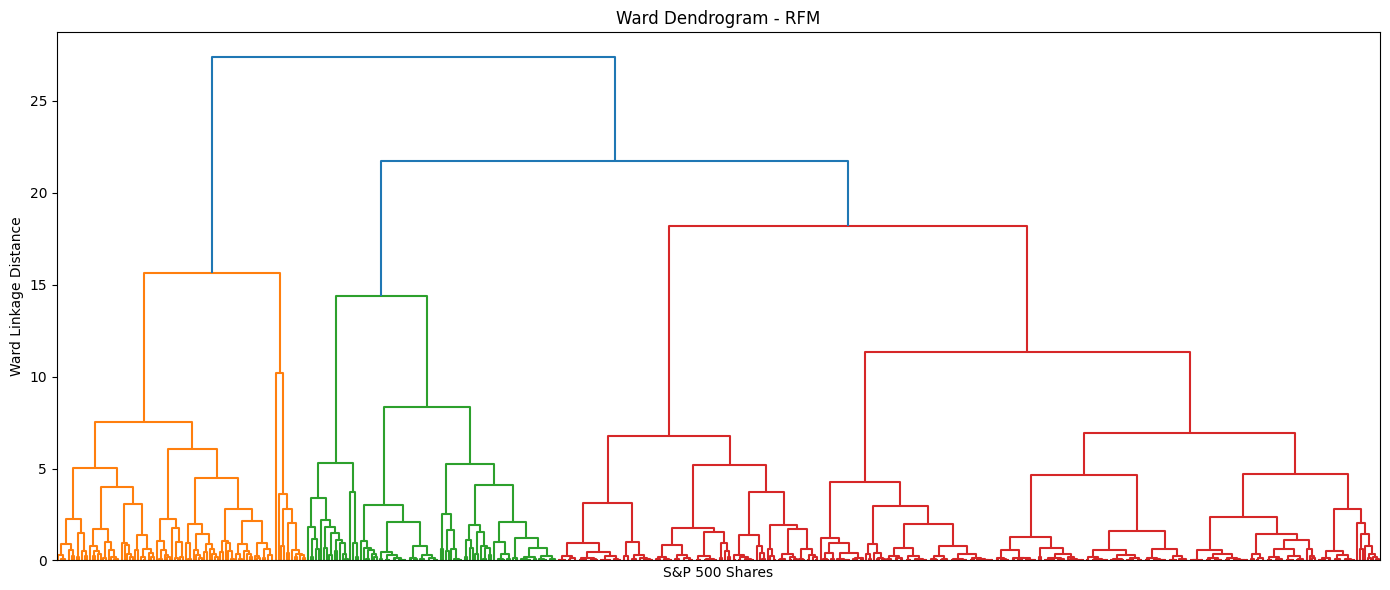

Both dendrograms saved successfully!


In [29]:

# Ward hierarchical clustering
risk_linkage = linkage(
    X_risk, method="ward", metric="euclidean"
)

rfm_linkage = linkage(
    X_rfm, method="ward", metric="euclidean"
)

# Risk-return dendrogram
plt.figure(figsize=(14, 6))
dendrogram(
    risk_linkage,
    no_labels=True
)

plt.title("Ward Dendrogram - Risk and Return")
plt.xlabel("S&P 500 Shares")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.savefig(
    "risk_return_dendrogram.png",
    dpi=300
)
plt.show()

# RFM dendrogram
plt.figure(figsize=(14, 6))
dendrogram(
    rfm_linkage,
    no_labels=True
)

plt.title("Ward Dendrogram - RFM")
plt.xlabel("S&P 500 Shares")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.savefig(
    "rfm_dendrogram.png",
    dpi=300
)
plt.show()

print("Both dendrograms saved successfully!")



### 2.2.1 Cluster Count Evaluation

Cluster counts from 2 to 8 are evaluated using silhouette scores and cluster sizes.


Ward clustering evaluation:


,Matrix,Clusters,Silhouette,SmallestCluster,LargestCluster
0,RiskReturn,2,0.288845,177,321
1,RiskReturn,3,0.320715,8,313
2,RiskReturn,4,0.297310,8,246
3,RiskReturn,5,0.288463,8,177
4,RiskReturn,6,0.289506,1,177
5,RiskReturn,7,0.296698,1,177
6,RiskReturn,8,0.279156,1,147
7,RFM,2,0.358679,94,404
8,RFM,3,0.316000,94,310
9,RFM,4,0.287608,94,211


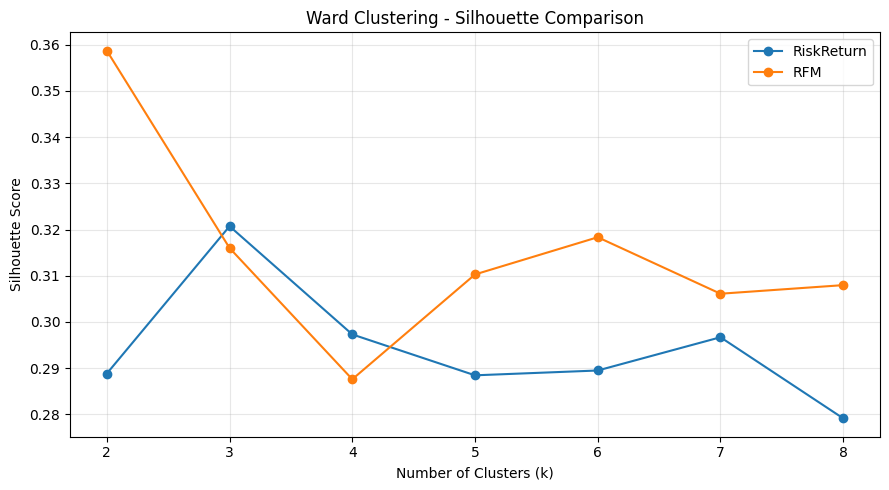

Ward evaluation completed!


In [30]:

ward_results = []

for matrix_name, X in [
    ("RiskReturn", X_risk),
    ("RFM", X_rfm)
]:
    for k in range(2, 9):

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward",
            metric="euclidean"
        )

        labels = model.fit_predict(X)

        score = silhouette_score(X, labels)
        sizes = pd.Series(labels).value_counts()

        ward_results.append({
            "Matrix": matrix_name,
            "Clusters": k,
            "Silhouette": score,
            "SmallestCluster": sizes.min(),
            "LargestCluster": sizes.max()
        })

ward_evaluation = pd.DataFrame(ward_results)

print("Ward clustering evaluation:")
display(ward_evaluation)

ward_evaluation.to_csv(
    "ward_cluster_evaluation.csv",
    index=False
)

# Visualise silhouette scores
plt.figure(figsize=(9, 5))

for name in ["RiskReturn", "RFM"]:
    subset = ward_evaluation[
        ward_evaluation["Matrix"] == name
    ]

    plt.plot(
        subset["Clusters"],
        subset["Silhouette"],
        marker="o",
        label=name
    )

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Ward Clustering - Silhouette Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "ward_silhouette_comparison.png",
    dpi=300
)

plt.show()

print("Ward evaluation completed!")



## 2.3 K-Means Clustering

K-Means clustering is applied to both standardised feature matrices, with cluster counts evaluated using silhouette scores, inertia and cluster sizes.


K-Means Clustering Evaluation:


,Matrix,Clusters,Silhouette,Inertia,SmallestCluster,LargestCluster
0,RiskReturn,2,0.399825,659.460945,147,351
1,RiskReturn,3,0.349059,498.106737,9,281
2,RiskReturn,4,0.336534,386.977294,8,192
3,RiskReturn,5,0.330316,318.804463,2,169
4,RiskReturn,6,0.350338,265.395041,2,175
5,RiskReturn,7,0.336710,225.456902,2,157
6,RiskReturn,8,0.330871,195.391643,2,131
7,RFM,2,0.418999,1094.049704,72,426
8,RFM,3,0.325170,818.241419,65,277
9,RFM,4,0.340100,625.239576,61,216


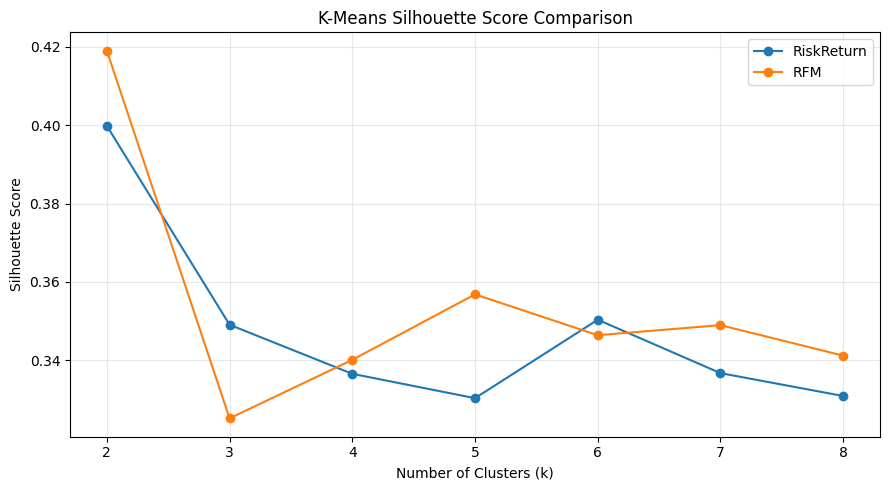

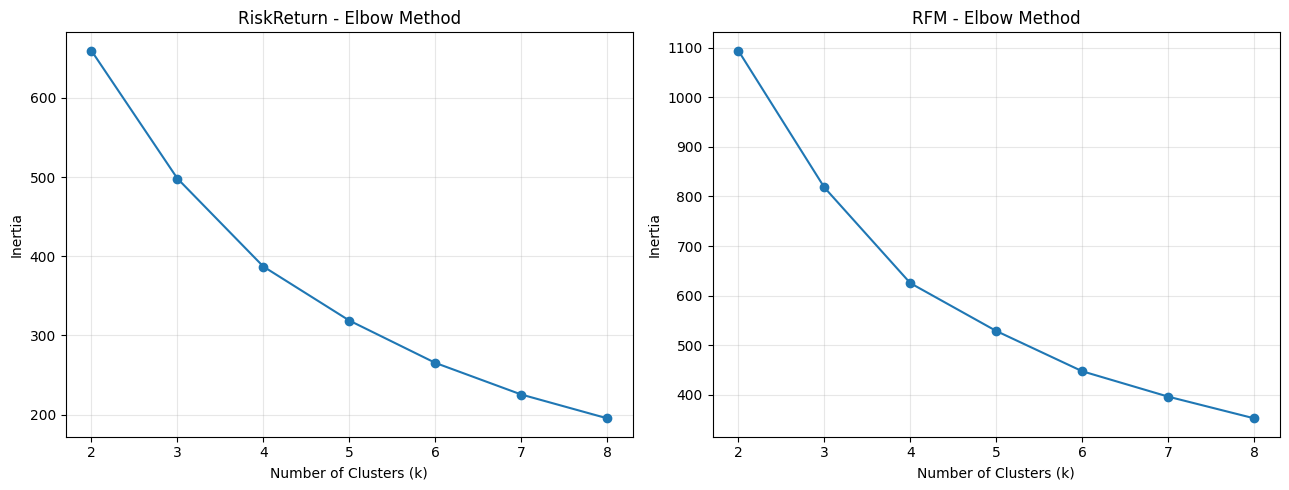

Task 2.3 K-Means evaluation completed!


In [31]:

# Task 2.3 - K-Means Clustering

kmeans_results = []

for matrix_name, X in [
    ("RiskReturn", X_risk),
    ("RFM", X_rfm)
]:

    for k in range(2, 9):

        # Set random seed and multiple initialisations
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        labels = model.fit_predict(X)

        # Evaluate clustering performance
        silhouette = silhouette_score(X, labels)

        sizes = pd.Series(labels).value_counts()

        kmeans_results.append({
            "Matrix": matrix_name,
            "Clusters": k,
            "Silhouette": silhouette,
            "Inertia": model.inertia_,
            "SmallestCluster": int(sizes.min()),
            "LargestCluster": int(sizes.max())
        })

# Convert results into a DataFrame
kmeans_evaluation = pd.DataFrame(kmeans_results)

print("K-Means Clustering Evaluation:")
display(kmeans_evaluation)

# Save evaluation table
kmeans_evaluation.to_csv(
    "kmeans_cluster_evaluation.csv",
    index=False
)

# Plot silhouette scores
plt.figure(figsize=(9, 5))

for name in ["RiskReturn", "RFM"]:

    subset = kmeans_evaluation[
        kmeans_evaluation["Matrix"] == name
    ]

    plt.plot(
        subset["Clusters"],
        subset["Silhouette"],
        marker="o",
        label=name
    )

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Score Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "kmeans_silhouette_comparison.png",
    dpi=300
)
plt.show()

# Plot inertia for both matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name in zip(axes, ["RiskReturn", "RFM"]):

    subset = kmeans_evaluation[
        kmeans_evaluation["Matrix"] == name
    ]

    ax.plot(
        subset["Clusters"],
        subset["Inertia"],
        marker="o"
    )

    ax.set_title(f"{name} - Elbow Method")
    ax.set_xlabel("Number of Clusters (k)")
    ax.set_ylabel("Inertia")
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "kmeans_elbow_comparison.png",
    dpi=300
)
plt.show()

print("Task 2.3 K-Means evaluation completed!")



## 2.4 Cluster Profiles and Algorithm Comparison

Ward and K-Means clustering results are compared using original feature values, cluster membership and two-dimensional visualisations.


In [32]:

# Selected cluster counts for comparison
k_ward_risk = 2
k_ward_rfm = 2
k_kmeans_risk = 2
k_kmeans_rfm = 2

# Fit Ward clustering
ward_risk = AgglomerativeClustering(
    n_clusters=k_ward_risk,
    linkage="ward",
    metric="euclidean"
).fit_predict(X_risk)

ward_rfm = AgglomerativeClustering(
    n_clusters=k_ward_rfm,
    linkage="ward",
    metric="euclidean"
).fit_predict(X_rfm)

# Fit K-Means clustering
kmeans_risk = KMeans(
    n_clusters=k_kmeans_risk,
    random_state=42,
    n_init=20
).fit_predict(X_risk)

kmeans_rfm = KMeans(
    n_clusters=k_kmeans_rfm,
    random_state=42,
    n_init=20
).fit_predict(X_rfm)

# Store the four cluster assignments
data["Ward_RiskReturn"] = ward_risk
data["Ward_RFM"] = ward_rfm
data["KMeans_RiskReturn"] = kmeans_risk
data["KMeans_RFM"] = kmeans_rfm

# Variables in their original units
profile_columns = [
    "MeanWeeklyReturnPct",
    "WeeklyBeta",
    "Recency",
    "Frequency",
    "Monetary"
]

# Create cluster profiles
all_profiles = []

for method in [
    "Ward_RiskReturn",
    "Ward_RFM",
    "KMeans_RiskReturn",
    "KMeans_RFM"
]:
    profile = data.groupby(method)[
        profile_columns
    ].mean()

    profile["ShareCount"] = data.groupby(method).size()
    profile["Method"] = method
    profile["Cluster"] = profile.index

    all_profiles.append(profile.reset_index(drop=True))

cluster_profiles = pd.concat(
    all_profiles, ignore_index=True
)

print("Cluster Profiles (Original Units):")
display(cluster_profiles.round(3))

# Compare algorithm memberships
ari_risk = adjusted_rand_score(
    ward_risk, kmeans_risk
)

ari_rfm = adjusted_rand_score(
    ward_rfm, kmeans_rfm
)

print("\nWard vs K-Means Agreement:")
print("Risk-Return ARI:", round(ari_risk, 4))
print("RFM ARI:", round(ari_rfm, 4))

# Save results
data.to_csv(
    "all_cluster_assignments.csv", index=False
)

cluster_profiles.to_csv(
    "cluster_profiles.csv", index=False
)

print("\nCluster profiles and assignments saved!")


Cluster Profiles (Original Units):


,MeanWeeklyReturnPct,WeeklyBeta,Recency,Frequency,Monetary,ShareCount,Method,Cluster
0,0.356,1.208,20.072,3.037,4.870978e+10,321,Ward_RiskReturn,0
1,0.208,0.579,21.305,2.944,2.311690e+10,177,Ward_RiskReturn,1
2,0.303,0.976,12.361,3.220,3.820898e+10,404,Ward_RFM,0
3,0.306,1.019,55.532,2.074,4.565006e+10,94,Ward_RFM,1
4,0.545,1.427,23.762,3.197,8.096921e+10,147,KMeans_RiskReturn,0
5,0.202,0.799,19.148,2.923,2.229362e+10,351,KMeans_RiskReturn,1
6,0.300,0.977,13.415,3.200,3.268613e+10,426,KMeans_RFM,0
7,0.327,1.027,62.486,1.847,8.060058e+10,72,KMeans_RFM,1



Ward vs K-Means Agreement:
Risk-Return ARI: 0.0763
RFM ARI: 0.7537

Cluster profiles and assignments saved!


RFM PCA explained variance:
[0.45658943 0.33904286]
Total: 0.7956322859324259


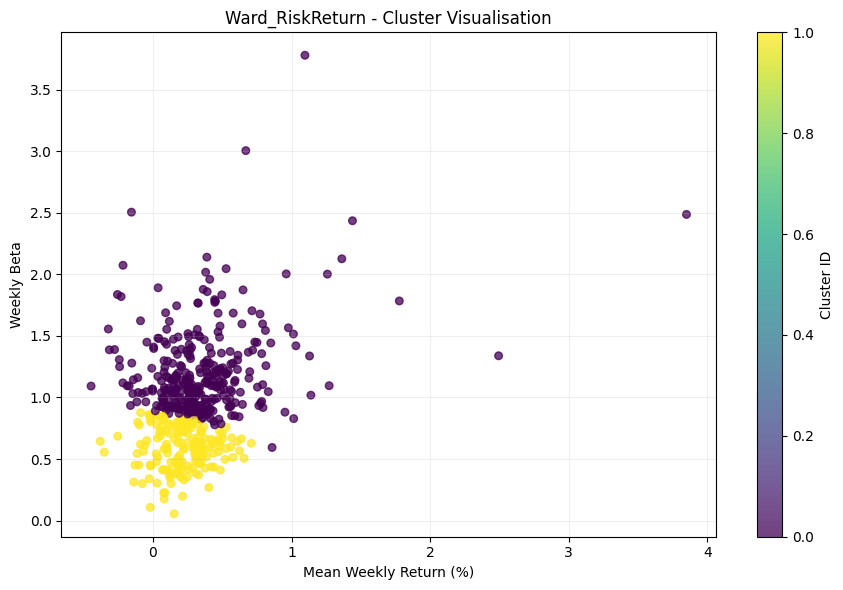

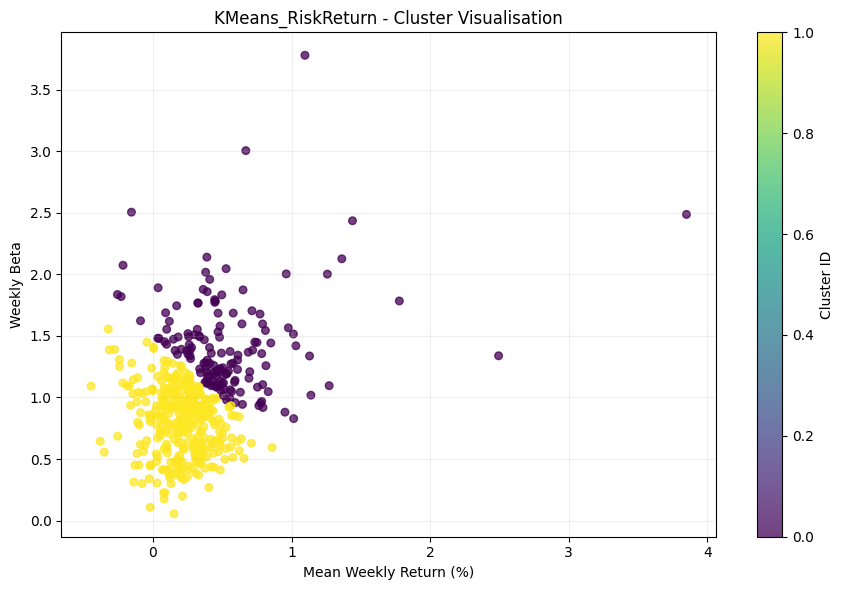

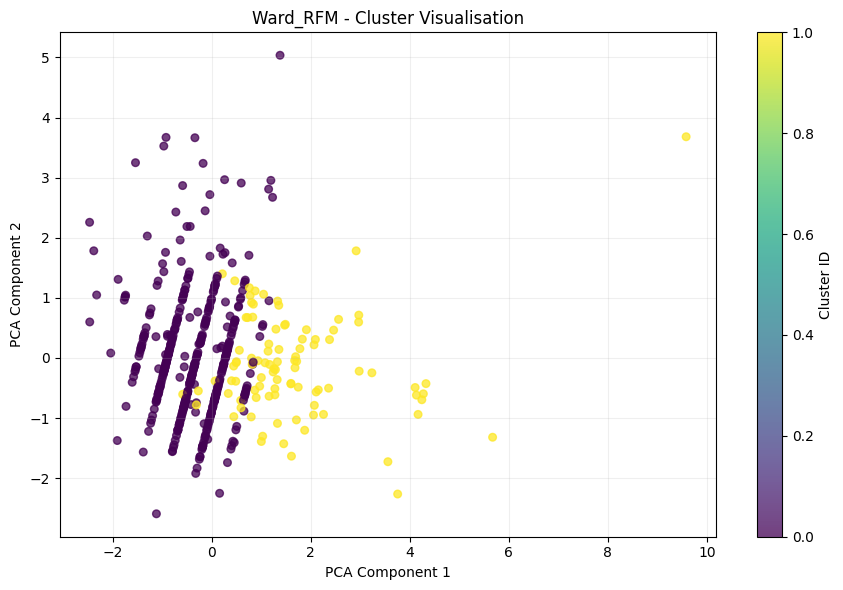

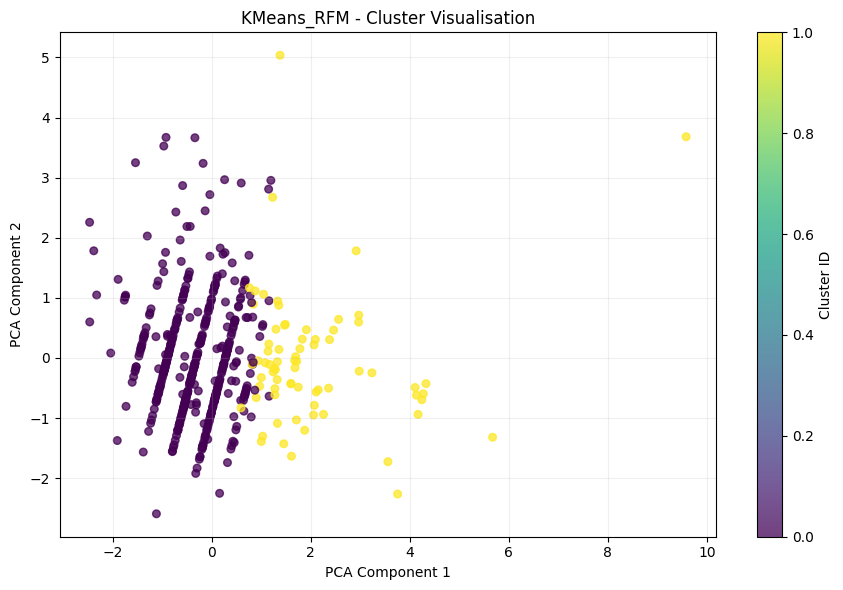

All four cluster visualisations saved!


In [33]:

# Risk-return plots use their two original features
# RFM plots use PCA for two-dimensional visualisation

# Fit PCA only for the RFM display
pca = PCA(n_components=2)
rfm_2d = pca.fit_transform(X_rfm)

print("RFM PCA explained variance:")
print(pca.explained_variance_ratio_)
print("Total:", pca.explained_variance_ratio_.sum())

plot_configs = [
    ("Ward_RiskReturn", "Risk-Return", ward_risk),
    ("KMeans_RiskReturn", "Risk-Return", kmeans_risk),
    ("Ward_RFM", "RFM", ward_rfm),
    ("KMeans_RFM", "RFM", kmeans_rfm)
]

for method, matrix_type, labels in plot_configs:

    plt.figure(figsize=(9, 6))

    if matrix_type == "Risk-Return":
        x = data["MeanWeeklyReturnPct"]
        y = data["WeeklyBeta"]
        xlabel = "Mean Weekly Return (%)"
        ylabel = "Weekly Beta"
    else:
        x = rfm_2d[:, 0]
        y = rfm_2d[:, 1]
        xlabel = "PCA Component 1"
        ylabel = "PCA Component 2"

    scatter = plt.scatter(
        x, y,
        c=labels,
        cmap="viridis",
        s=30,
        alpha=0.75
    )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(f"{method} - Cluster Visualisation")
    plt.colorbar(scatter, label="Cluster ID")
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        f"{method}_clusters.png",
        dpi=300
    )

    plt.show()

print("All four cluster visualisations saved!")



## 2.5 RFM Sensitivity and Correlated Inputs
### 2.5.1 Correlation Analysis

Correlations between Recency, Frequency and log-transformed Monetary are examined to identify overlapping information.


RFM Correlation Matrix:


,Recency,Frequency,LogMonetary
Recency,1.0000,-0.3402,0.1647
Frequency,-0.3402,1.0000,0.0219
LogMonetary,0.1647,0.0219,1.0000


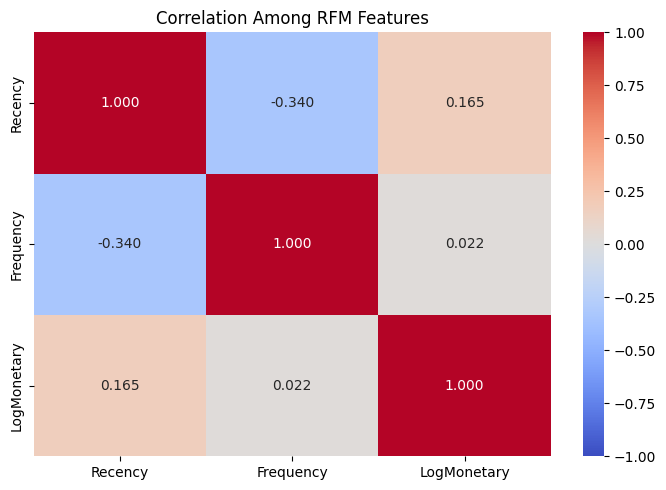

Correlation analysis completed!


In [34]:

# Prepare RFM features for correlation analysis
correlation_data = data[
    ["Recency", "Frequency", "Monetary"]
].copy()

# Apply the same Monetary transformation
correlation_data["LogMonetary"] = np.log1p(
    correlation_data["Monetary"]
)

# Calculate Pearson correlations
rfm_correlation = correlation_data[
    ["Recency", "Frequency", "LogMonetary"]
].corr(method="pearson")

print("RFM Correlation Matrix:")
display(rfm_correlation.round(4))

# Create correlation heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    rfm_correlation,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Among RFM Features")
plt.tight_layout()

plt.savefig(
    "rfm_correlation_heatmap.png",
    dpi=300
)

plt.show()

# Save results
rfm_correlation.to_csv(
    "rfm_correlation_matrix.csv"
)

print("Correlation analysis completed!")



### 2.5.2 Removal of Monetary

Ward RFM clustering is repeated using only Recency and Frequency to assess changes in cluster membership after removing Monetary.


In [35]:

# Use the same shares as the original Ward RFM model
rf_only = data[["Recency", "Frequency"]].copy()

# Standardise the reduced feature matrix again
rf_scaler = StandardScaler()
X_rf = rf_scaler.fit_transform(rf_only)

# Use the same cluster count as original Ward RFM
rf_model = AgglomerativeClustering(
    n_clusters=k_ward_rfm,
    linkage="ward",
    metric="euclidean"
)

rf_labels = rf_model.fit_predict(X_rf)

# Save new cluster membership
data["Ward_RF_WithoutMonetary"] = rf_labels

# Compare with original Ward RFM
ari_monetary = adjusted_rand_score(
    data["Ward_RFM"],
    data["Ward_RF_WithoutMonetary"]
)

print("Monetary Removal Sensitivity Analysis")
print("Number of shares:", len(data))
print("Number of clusters:", k_ward_rfm)
print("Adjusted Rand Index:", round(ari_monetary, 4))

# Compare cluster sizes
print("\nOriginal Ward RFM cluster sizes:")
display(data["Ward_RFM"].value_counts().sort_index())

print("\nWard RF cluster sizes without Monetary:")
display(
    data["Ward_RF_WithoutMonetary"]
    .value_counts()
    .sort_index()
)

# Compare membership cross-tabulation
comparison = pd.crosstab(
    data["Ward_RFM"],
    data["Ward_RF_WithoutMonetary"],
    rownames=["Original RFM"],
    colnames=["Without Monetary"]
)

print("\nCluster membership comparison:")
display(comparison)

# Compare Monetary values in original units
original_profile = data.groupby("Ward_RFM").agg(
    ShareCount=("Ticker", "size"),
    MeanRecency=("Recency", "mean"),
    MeanFrequency=("Frequency", "mean"),
    MeanMonetaryUSD=("Monetary", "mean"),
    MedianMonetaryUSD=("Monetary", "median")
)

reduced_profile = data.groupby(
    "Ward_RF_WithoutMonetary"
).agg(
    ShareCount=("Ticker", "size"),
    MeanRecency=("Recency", "mean"),
    MeanFrequency=("Frequency", "mean"),
    MeanMonetaryUSD=("Monetary", "mean"),
    MedianMonetaryUSD=("Monetary", "median")
)

print("\nOriginal RFM cluster profiles:")
display(original_profile)

print("\nWithout Monetary cluster profiles:")
display(reduced_profile)

# Save evidence
comparison.to_csv("rfm_monetary_removal_crosstab.csv")
original_profile.to_csv("ward_rfm_original_profiles.csv")
reduced_profile.to_csv("ward_rf_reduced_profiles.csv")
data.to_csv("all_cluster_assignments.csv", index=False)

print("\nMonetary sensitivity analysis completed!")


Monetary Removal Sensitivity Analysis
Number of shares: 498
Number of clusters: 2
Adjusted Rand Index: 0.9531

Original Ward RFM cluster sizes:


,count
Ward_RFM,
0,404
1,94



Ward RF cluster sizes without Monetary:


,count
Ward_RF_WithoutMonetary,
0,405
1,93



Cluster membership comparison:


Without Monetary,0,1
Original RFM,,
0,402,2
1,3,91



Original RFM cluster profiles:


,ShareCount,MeanRecency,MeanFrequency,MeanMonetaryUSD,MedianMonetaryUSD
Ward_RFM,,,,,
0,404,12.361386,3.220297,3.820898e+10,1.547309e+10
1,94,55.531915,2.074468,4.565006e+10,2.095020e+10



Without Monetary cluster profiles:


,ShareCount,MeanRecency,MeanFrequency,MeanMonetaryUSD,MedianMonetaryUSD
Ward_RF_WithoutMonetary,,,,,
0,405,12.353086,3.222222,3.768854e+10,1.545679e+10
1,93,56.032258,2.053763,4.799647e+10,2.105259e+10



Monetary sensitivity analysis completed!



# Task 3 — Business Intelligence and Critical Review



# Task 3 — Business Intelligence and Critical Review
## 3.1 Data Mart Design
### 3.1.1 Grain, Facts and Dimensions
### 3.1.2 Provenance and Calculation History
### 3.1.3 Analytical and Stakeholder Support

In [36]:

!pip -q install graphviz


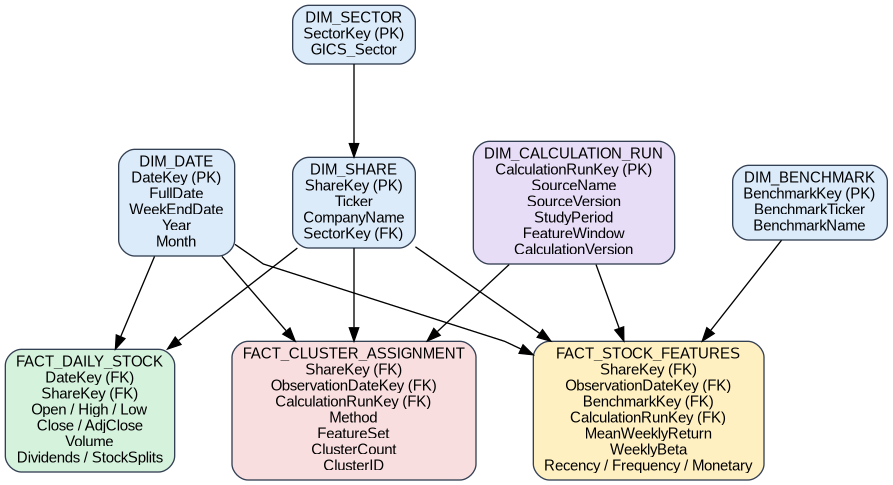

Task 3.1 Data Mart Diagram Created!


In [37]:

# Task 3.1 - Data Mart Design Diagram

from graphviz import Digraph
from IPython.display import display, Image

dot = Digraph("Stock_Data_Mart", format="png")

dot.attr(rankdir="TB", splines="polyline",
         nodesep="0.6", ranksep="0.8")

dot.attr("node", shape="box", style="rounded,filled",
         fontname="Arial", fontsize="11",
         color="#344054")

# Dimensions
dot.node("Date",
         "DIM_DATE\n"
         "DateKey (PK)\n"
         "FullDate\nWeekEndDate\nYear\nMonth",
         fillcolor="#DCEBFA")

dot.node("Share",
         "DIM_SHARE\n"
         "ShareKey (PK)\n"
         "Ticker\nCompanyName\nSectorKey (FK)",
         fillcolor="#DCEBFA")

dot.node("Sector",
         "DIM_SECTOR\n"
         "SectorKey (PK)\nGICS_Sector",
         fillcolor="#DCEBFA")

dot.node("Benchmark",
         "DIM_BENCHMARK\n"
         "BenchmarkKey (PK)\n"
         "BenchmarkTicker\nBenchmarkName",
         fillcolor="#DCEBFA")

# Daily fact table
dot.node("Daily",
         "FACT_DAILY_STOCK\n"
         "DateKey (FK)\nShareKey (FK)\n"
         "Open / High / Low\n"
         "Close / AdjClose\nVolume\n"
         "Dividends / StockSplits",
         fillcolor="#D5F2DC")

# Derived features
dot.node("Features",
         "FACT_STOCK_FEATURES\n"
         "ShareKey (FK)\n"
         "ObservationDateKey (FK)\n"
         "BenchmarkKey (FK)\n"
         "CalculationRunKey (FK)\n"
         "MeanWeeklyReturn\nWeeklyBeta\n"
         "Recency / Frequency / Monetary",
         fillcolor="#FFF0C2")

# Provenance and model history
dot.node("Run",
         "DIM_CALCULATION_RUN\n"
         "CalculationRunKey (PK)\n"
         "SourceName\nSourceVersion\n"
         "StudyPeriod\nFeatureWindow\n"
         "CalculationVersion",
         fillcolor="#E7DDF7")

dot.node("Cluster",
         "FACT_CLUSTER_ASSIGNMENT\n"
         "ShareKey (FK)\n"
         "ObservationDateKey (FK)\n"
         "CalculationRunKey (FK)\n"
         "Method\nFeatureSet\n"
         "ClusterCount\nClusterID",
         fillcolor="#F9DEDF")

# Relationships
dot.edge("Date", "Daily")
dot.edge("Share", "Daily")
dot.edge("Sector", "Share")

dot.edge("Date", "Features")
dot.edge("Share", "Features")
dot.edge("Benchmark", "Features")
dot.edge("Run", "Features")

dot.edge("Share", "Cluster")
dot.edge("Date", "Cluster")
dot.edge("Run", "Cluster")

# Export diagram
dot.render("task_3_1_data_mart", cleanup=True)

display(Image(filename="task_3_1_data_mart.png"))

print("Task 3.1 Data Mart Diagram Created!")



## 3.2 Review of Results and Visualisation
### 3.2.1 Cluster Profiles and Sector Composition


Shares with missing sector information:
0

Ward_RiskReturn - Sector Composition (%)


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RiskReturn,,,,,,,,,,,
0,4.05,12.46,1.25,3.43,16.51,9.03,19.63,21.81,4.67,5.92,1.25
1,5.08,3.95,15.82,5.65,12.99,17.51,10.17,2.26,5.08,6.21,15.25


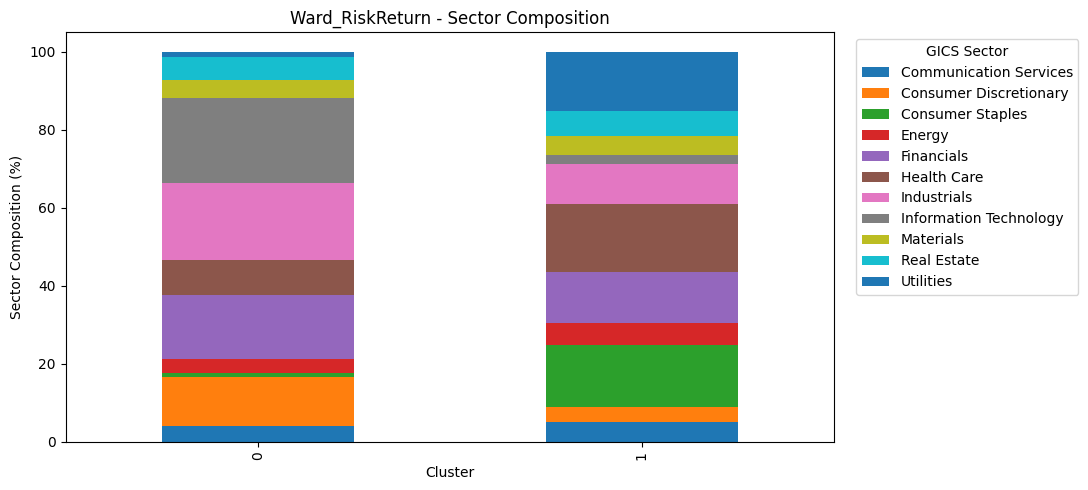


KMeans_RiskReturn - Sector Composition (%)


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RiskReturn,,,,,,,,,,,
0,4.76,14.29,0.68,3.40,13.61,1.36,19.05,35.37,3.40,2.04,2.04
1,4.27,7.41,8.83,4.56,15.95,16.52,15.10,6.27,5.41,7.69,7.98


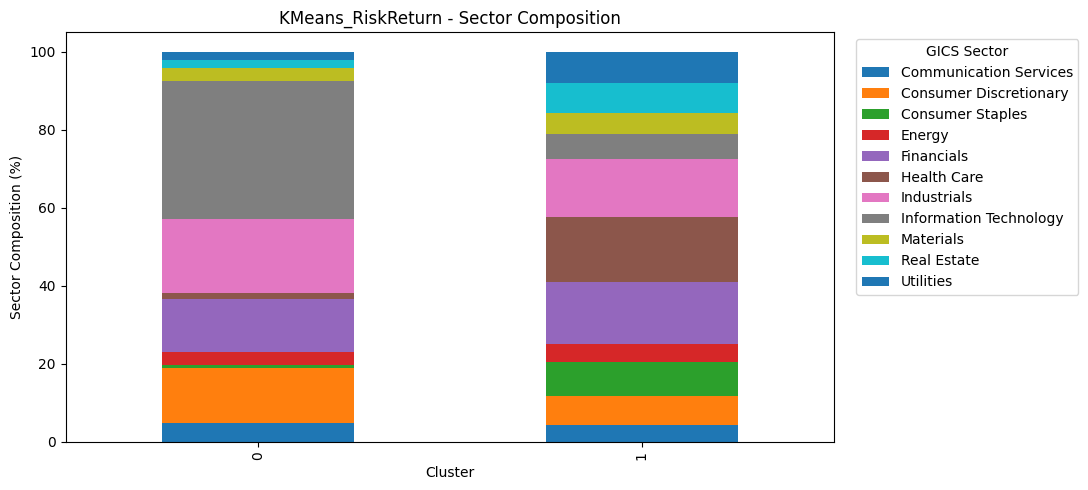


Ward_RFM - Sector Composition (%)


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RFM,,,,,,,,,,,
0,4.46,9.16,5.94,4.70,15.35,12.62,17.82,13.37,3.96,7.43,5.20
1,4.26,10.64,8.51,2.13,14.89,9.57,9.57,21.28,8.51,0.00,10.64


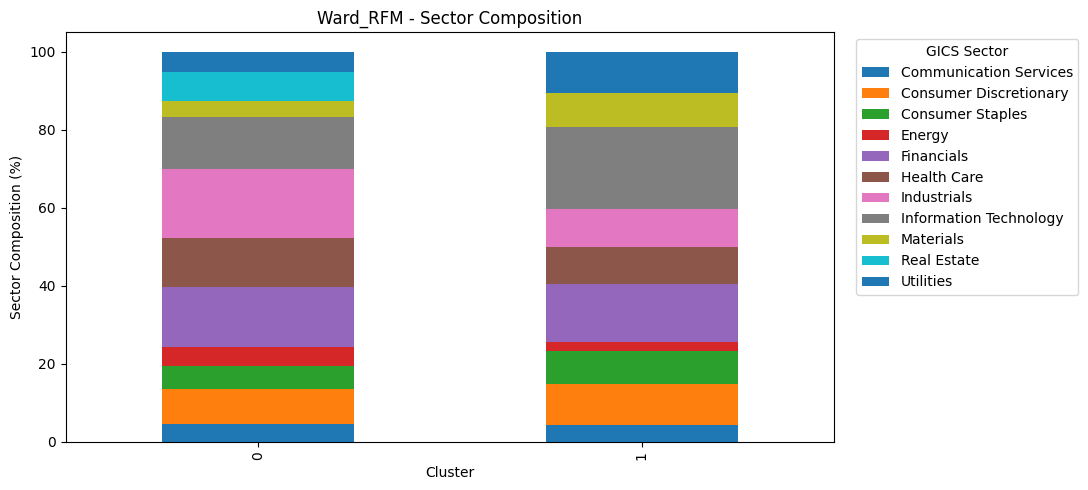


KMeans_RFM - Sector Composition (%)


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RFM,,,,,,,,,,,
0,4.69,9.15,6.34,4.69,15.02,12.21,17.84,13.85,4.23,7.04,4.93
1,2.78,11.11,6.94,1.39,16.67,11.11,6.94,20.83,8.33,0.00,13.89


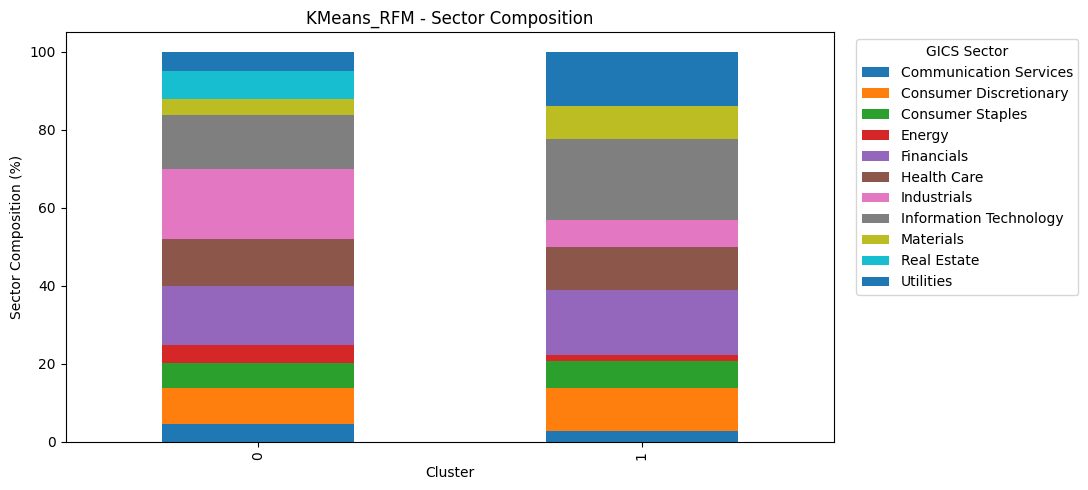


All sector composition tables and charts saved!


In [38]:

# Combine cluster assignments with company sector information

sector_info = sp500[
    ["YahooTicker", "Security", "GICS Sector"]
].drop_duplicates("YahooTicker").copy()

sector_info = sector_info.rename(
    columns={"YahooTicker": "Ticker"}
)

sector_data = data.merge(
    sector_info,
    on="Ticker",
    how="left",
    validate="many_to_one"
)

print("Shares with missing sector information:")
print(sector_data["GICS Sector"].isna().sum())

# Sector composition for all four clustering methods
sector_tables = {}

for method in [
    "Ward_RiskReturn",
    "KMeans_RiskReturn",
    "Ward_RFM",
    "KMeans_RFM"
]:

    counts = pd.crosstab(
        sector_data[method],
        sector_data["GICS Sector"]
    )

    percentages = pd.crosstab(
        sector_data[method],
        sector_data["GICS Sector"],
        normalize="index"
    ) * 100

    sector_tables[method] = percentages

    print(f"\n{method} - Sector Composition (%)")
    display(percentages.round(2))

    counts.to_csv(f"{method}_sector_counts.csv")
    percentages.to_csv(
        f"{method}_sector_percentages.csv"
    )

    # Visualise the share of each sector by cluster
    ax = percentages.plot(
        kind="bar",
        stacked=True,
        figsize=(11, 5)
    )

    ax.set_title(f"{method} - Sector Composition")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Sector Composition (%)")
    ax.legend(
        title="GICS Sector",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.savefig(
        f"{method}_sector_composition.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

print("\nAll sector composition tables and charts saved!")
